# Lab 1: Spatial Deep Learning Regression on California Housing (GIS data)

Predict median house value from census block attributes and location using a 3 layer
deep neural network in TensorFlow/Keras. The data is a point shapefile, so the
pipeline reads it with GeoPandas, cleans capped values, engineers coordinate features
from the geometry, and trains a regression model.

**Run in Google Colab.** Upload `california_housing.shp` and its sidecar files
(`.shx`, `.dbf`, `.prj`) to the session, or mount Google Drive and set `DATA_PATH`.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = "california_housing.shp"   # change if the file lives elsewhere

## Task 1: Load and preprocess the data

In [2]:
housing = gpd.read_file(DATA_PATH)
print(housing.shape)
print(housing.crs)
housing.head()

(20640, 9)
EPSG:4326


,total_room,total_bedr,population,households,median_inc,ocean_prox,house_age,median_val,geometry
0,880.0,129.0,322.0,126.0,83252.0,NEAR BAY,41.0,452600.0,POINT (-122.23 37.88)
1,7099.0,1106.0,2401.0,1138.0,83014.0,NEAR BAY,21.0,358500.0,POINT (-122.22 37.86)
2,1467.0,190.0,496.0,177.0,72574.0,NEAR BAY,52.0,352100.0,POINT (-122.24 37.85)
3,1274.0,235.0,558.0,219.0,56431.0,NEAR BAY,52.0,341300.0,POINT (-122.25 37.85)
4,1627.0,280.0,565.0,259.0,38462.0,NEAR BAY,52.0,342200.0,POINT (-122.25 37.85)


In [3]:
# Remove artificially capped values (the census data caps age at 52 and value at 500,001)
clean = housing[(housing["house_age"] < 52) & (housing["median_val"] < 500001)].copy()

# One hot encode ocean proximity
clean = pd.get_dummies(clean, columns=["ocean_prox"], dtype="float32")

# Coordinates from the point geometry, then drop the geometry column
clean["longitude"] = clean.geometry.x
clean["latitude"] = clean.geometry.y
clean = pd.DataFrame(clean.drop(columns="geometry"))

print(f"Rows after cleaning: {len(clean):,} (removed {len(housing) - len(clean):,})")

Rows after cleaning: 18,572 (removed 2,068)


## Task 2: Train/test split and scaling

In [4]:
TARGET = "median_val"
X = clean.drop(columns=[TARGET])
y = clean[TARGET].astype("float32") / 100_000      # train in units of $100k for stable optimisation

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

dummy_cols = [c for c in X.columns if c.startswith("ocean_prox")]
num_cols = [c for c in X.columns if c not in dummy_cols]

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
# Scaling keeps the original row index, so features stay aligned with their targets
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

X_train_s = X_train_s.astype("float32")
X_test_s = X_test_s.astype("float32")
print(X_train_s.shape, X_test_s.shape)

(14857, 13) (3715, 13)


## Task 3: Build and train a 3 layer DNN

In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_s.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")

early_stop = tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train_s, y_train, epochs=100, batch_size=64,
                    validation_split=0.2, callbacks=[early_stop], verbose=0)
print(f"Trained for {len(history.history['loss'])} epochs")

Trained for 56 epochs


## Task 4: Training and validation loss

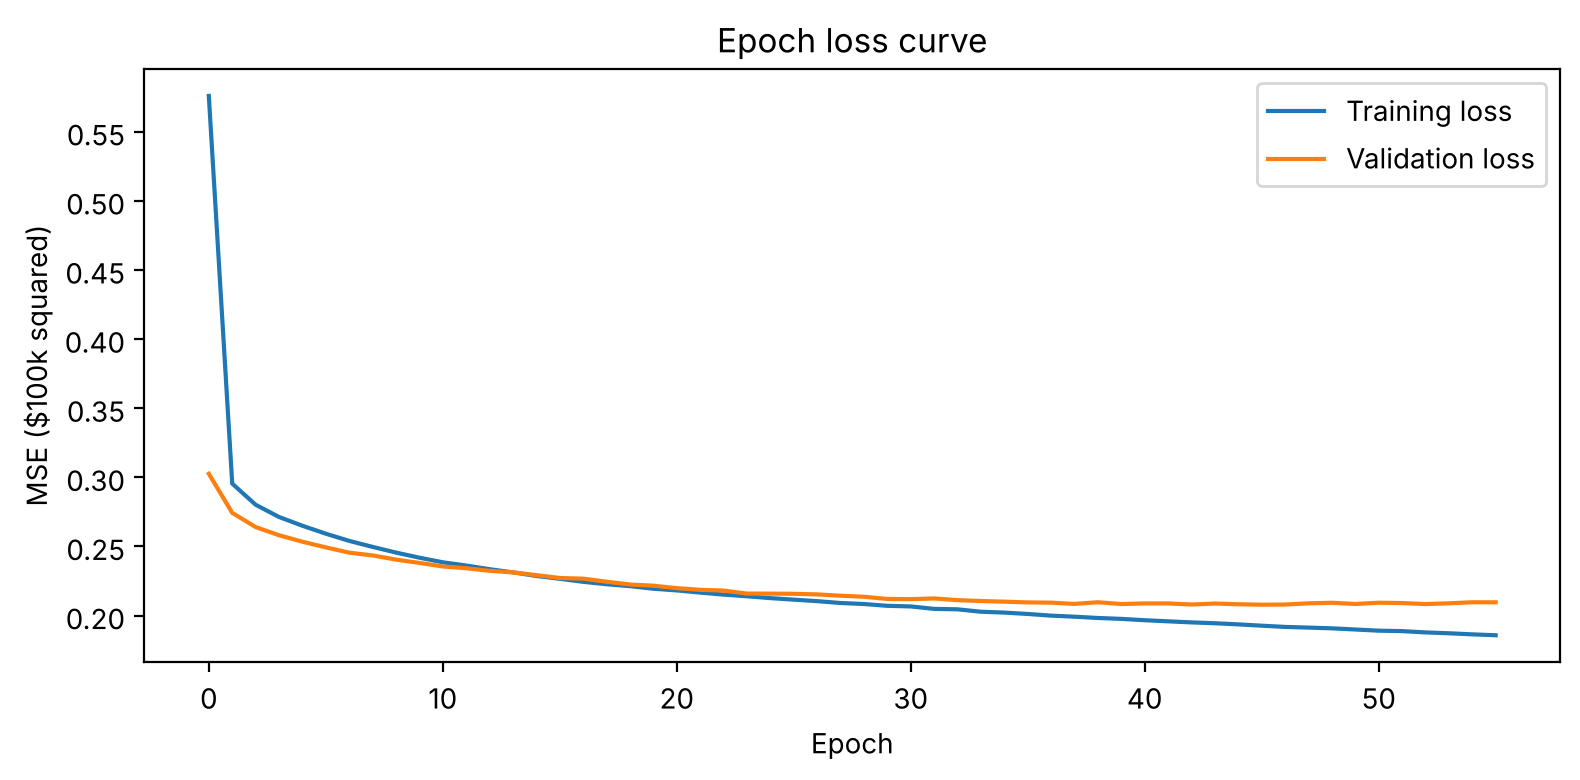

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE ($100k squared)")
plt.title("Epoch loss curve")
plt.legend(); plt.tight_layout(); plt.show()

## Task 5: Test RMSE

In [7]:
y_pred = model.predict(X_test_s, verbose=0).ravel()
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) * 100_000
print(f"Test RMSE: ${rmse:,.0f}")

Test RMSE: $47,915


## Baseline: linear regression on the same features and split

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lin = LinearRegression().fit(X_train_s, y_train)
lin_pred = lin.predict(X_test_s)
lin_rmse = np.sqrt(mean_squared_error(y_test, lin_pred)) * 100_000

print(f"Linear regression: RMSE ${lin_rmse:,.0f}, R2 {r2_score(y_test, lin_pred):.3f}")
print(f"Neural network:    RMSE ${rmse:,.0f}, R2 {r2_score(y_test, y_pred):.3f}")
print(f"The neural network lowers RMSE by {(lin_rmse - rmse) / lin_rmse:.0%}")

Linear regression: RMSE $59,820, R2 0.624
Neural network:    RMSE $47,915, R2 0.759
The neural network lowers RMSE by 20%


## Task 6: Predicted vs true values

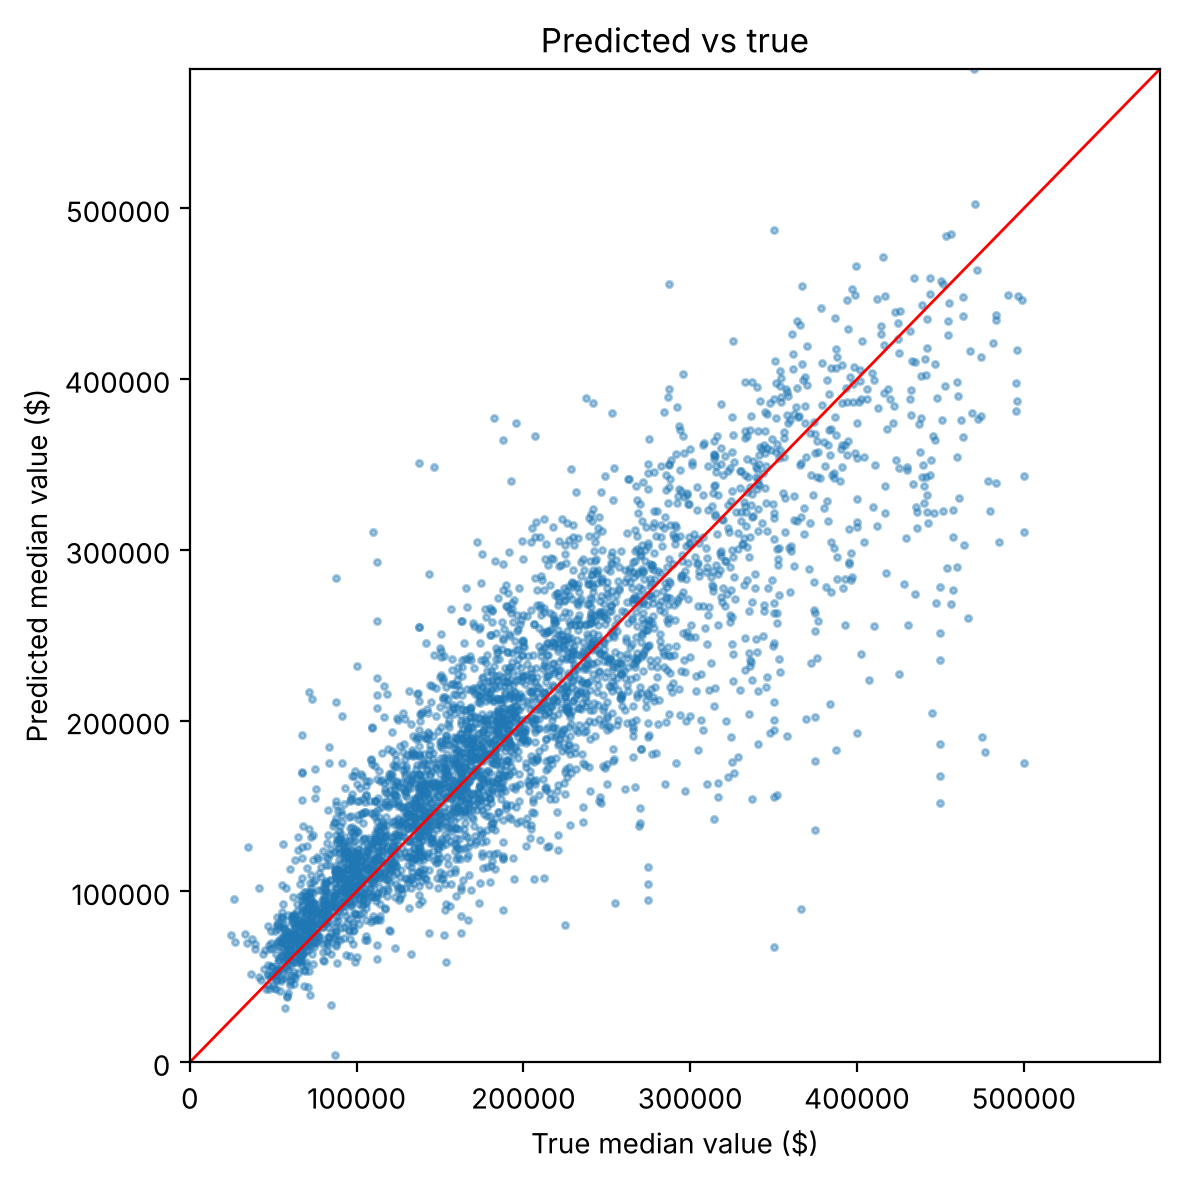

In [9]:
true_vals = y_test.values * 100_000
pred_vals = y_pred * 100_000
lim = [0, max(true_vals.max(), pred_vals.max())]

plt.figure(figsize=(6, 6))
plt.scatter(true_vals, pred_vals, s=5, alpha=0.4)
plt.plot(lim, lim, color="red", linewidth=1)
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("True median value ($)"); plt.ylabel("Predicted median value ($)")
plt.title("Predicted vs true")
plt.tight_layout(); plt.show()